# What holds a co-review network together? Taste, time, or social play on Food.com

**02805 Social Graphs and Interactions — final project (main analysis)**

**Research question.** Communities in a co-review network are usually read as groups of users with similar culinary taste (the assumption behind collaborative filtering). Do the communities of active Food.com users reflect **taste**, **when users joined**, or **social ties** such as forum games? And does the **review text** reveal which?

**Starting hypothesis (H0):** communities reflect culinary taste.

**Pipeline**
1. Bipartite user–recipe network (a user is linked to every recipe they reviewed).
2. Active core: users with ≥ `KU` recipes, recipes with ≥ `KR` reviewers (iterative filter).
3. Projection to a user–user network (weight = recipes reviewed in common).
4. Backbone with the disparity filter (significance level `ALPHA`).
5. Louvain communities, compared with a degree-preserving null model.
6. Text: game markers, a review-text classifier, ratings.

| Section | Question |
|---|---|
| 1–3 | Data, network and communities |
| 4 | Are the communities real? (null model) |
| 5 | Are they stable? Does the game community always reappear? |
| 6 | Are communities just cohorts of users who joined at the same time? |
| 7 | How much forum-game activity is there, and are the markers valid? |
| 8 | Does the review text reveal the community? |
| 9 | Do game reviews give higher ratings? |
| 10 | Hand-labelled validation |
| 11 | Paper figures and summary |

## 1. Setup

In [1]:
import os, ast, re, json, time, warnings
from collections import Counter
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Patch
from scipy import sparse
from scipy.stats import ks_2samp
from sklearn.metrics import normalized_mutual_info_score, cohen_kappa_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, cross_val_predict
warnings.filterwarnings("ignore")

DATA_DIR = "data"
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
SEED = 42                      # fixed seed: every run gives the same results
rng = np.random.default_rng(SEED)
S = {}                         # summary of key numbers (printed at the end)

# Network parameters (justified in sections 2 and 5)
KU, KR, ALPHA = 20, 10, 0.05   # min recipes per user, min reviewers per recipe, disparity-filter significance
N_SEEDS = 10                   # Louvain runs
N_NULL = 20                    # degree-preserving null networks

# Forum-game markers. Derived from (i) the most distinctive words of the game community in the
# exploration notebook, (ii) games named in the reviews themselves ("Made for ZWT8"),
# (iii) external sources on the Zaar World Tour. Validated in section 7 and by hand in section 10.
GAME_PATTERNS = [r"\bzwt\s?\d*\b", r"zaar world tour", r"\bpac\b", r"pick[- ]a[- ]chef",
                 r"\btag(ged|ging)?\b", r"\bswap(ped)?\b", r"\bcookathon\b"]
GAME_RE = re.compile("|".join(GAME_PATTERNS), re.I)

# Names and colours used in all figures. >>> Check that the IDs match your communities (section 3) <<<
LABELS = {0: "Mainstream", 1: "Early cohort", 2: "Forum games", 3: "Small circle"}
COLORS = {0: "#a8a7a1", 1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}  # grey = mainstream; CVD-validated palette
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.titleweight": "bold", "axes.titlesize": 11})

def savefig(name):
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200); plt.show()

## 2. Data and the bipartite user–recipe network

In [2]:
t0 = time.time()
recipes = pd.read_csv(f"{DATA_DIR}/RAW_recipes.csv")
recipes["tags"] = recipes["tags"].apply(lambda s: ast.literal_eval(s) if isinstance(s, str) else [])
inter = pd.read_csv(f"{DATA_DIR}/RAW_interactions.csv")
inter["date"] = pd.to_datetime(inter["date"], errors="coerce")
inter["review"] = inter["review"].fillna("").astype(str)
inter["n_words"] = inter["review"].str.split().str.len().fillna(0).astype(int)

# One edge per (user, recipe); flag reviews that contain a game marker (used only from section 5 on)
edges = inter.drop_duplicates(["user_id", "recipe_id"]).reset_index(drop=True)
edges["game"] = edges["review"].str.contains(GAME_RE)

user_deg = edges.groupby("user_id").size()
S["data"] = dict(users=int(inter["user_id"].nunique()), recipes=int(recipes["id"].nunique()),
                 reviews=int(len(inter)), pct_users_one_review=round(100 * float((user_deg == 1).mean()), 1),
                 pct_five_stars=round(100 * float((inter["rating"] == 5).mean()), 1),
                 pct_reviews_with_game_marker=round(100 * float(edges["game"].mean()), 2))
print(f"Loaded in {time.time()-t0:.0f}s:", S["data"])

Loaded in 66s: {'users': 226570, 'recipes': 231637, 'reviews': 1132367, 'pct_users_one_review': 73.4, 'pct_five_stars': 72.1, 'pct_reviews_with_game_marker': 7.87}


Most users wrote a single review and add no structure, so we keep the **active core**: an iterative filter on the bipartite network that keeps users with ≥ `KU` recipes and recipes with ≥ `KR` reviewers. `KU = 20, KR = 10` gives ≈ 3,500 users, within the size range recommended by the course. Other values are tested in section 5.

## 3. User–user network, backbone and Louvain communities

In [3]:
def bipartite_core(df, ku, kr, max_iter=100):
    # Iteratively drop users with < ku recipes and recipes with < kr users until nothing changes
    d = df
    for _ in range(max_iter):
        keep = (d["user_id"].map(d["user_id"].value_counts()) >= ku) & \
               (d["recipe_id"].map(d["recipe_id"].value_counts()) >= kr)
        if keep.all(): break
        d = d[keep]
    return d.copy()

def project_users(ui, ri, nu, nr):
    # User-user projection: weight = number of recipes reviewed in common
    B = sparse.csr_matrix((np.ones(len(ui)), (ui, ri)), shape=(nu, nr))
    W = sparse.triu(B @ B.T, k=1).tocoo()
    return W.row, W.col, W.data

def disparity_filter(row, col, w, n, alpha):
    # Serrano et al. (2009): keep an edge if its share of the node's strength is significant
    # under a null where strength is spread uniformly over the node's edges (at either end)
    s = np.bincount(row, weights=w, minlength=n) + np.bincount(col, weights=w, minlength=n)
    k = np.bincount(row, minlength=n) + np.bincount(col, minlength=n)
    return ((1 - w / s[row]) ** (k[row] - 1) < alpha) | ((1 - w / s[col]) ** (k[col] - 1) < alpha)

def backbone(row, col, w, n, alpha):
    keep = disparity_filter(row, col, w, n, alpha)
    G = nx.Graph(); G.add_weighted_edges_from(zip(row[keep].tolist(), col[keep].tolist(), w[keep].tolist()))
    return G.subgraph(max(nx.connected_components(G), key=len)).copy()

def build_network(ku, kr, alpha):
    core = bipartite_core(edges, ku, kr)
    users = np.sort(core["user_id"].unique()); recs = np.sort(core["recipe_id"].unique())
    core["ui"] = core["user_id"].map({u: i for i, u in enumerate(users)})
    core["ri"] = core["recipe_id"].map({r: i for i, r in enumerate(recs)})
    row, col, w = project_users(core["ui"].values, core["ri"].values, len(users), len(recs))
    return core, row, col, w, len(users), len(recs)

def louvain(G, seed):
    parts = sorted(nx.community.louvain_communities(G, weight="weight", seed=seed), key=len, reverse=True)
    return {n: i for i, p in enumerate(parts) for n in p}, nx.community.modularity(G, parts, weight="weight")

core, row, col, w, nu, nr = build_network(KU, KR, ALPHA)
S["core"] = dict(users=nu, recipes=nr, edges=len(core))
S["projection"] = dict(edges=int(len(w)), density=round(2 * len(w) / (nu * (nu - 1)), 3))

# Choice of ALPHA: smallest value that keeps (almost) all users in the giant component
bb = []
for a in [0.01, 0.05, 0.10]:
    keep = disparity_filter(row, col, w, nu, a)
    Gt = nx.Graph(); Gt.add_nodes_from(range(nu)); Gt.add_edges_from(zip(row[keep], col[keep]))
    bb.append(dict(alpha=a, edges=int(keep.sum()), pct_users_in_giant=round(100 * len(max(nx.connected_components(Gt), key=len)) / nu, 1)))
S["alpha_choice"] = bb
print("Core:", S["core"], "| projection:", S["projection"]); print(pd.DataFrame(bb))

Core: {'users': 3477, 'recipes': 10636, 'edges': 237320} | projection: {'edges': 2799026, 'density': 0.463}
   alpha   edges  pct_users_in_giant
0   0.01   35503                98.4
1   0.05  130905               100.0
2   0.10  258455               100.0


In [4]:
Gu = backbone(row, col, w, nu, ALPHA)
runs = {s: louvain(Gu, s) for s in range(N_SEEDS)}
best_seed = max(runs, key=lambda s: runs[s][1])
comm_of, Q = runs[best_seed]
core["comm"] = core["ui"].map(comm_of)
cc = core.dropna(subset=["comm"]).copy(); cc["comm"] = cc["comm"].astype(int)
sizes = cc.groupby("comm")["ui"].nunique()
BIG = [c for c in sizes.index if sizes[c] >= 30]          # communities with ≥ 30 users
cc = cc[cc["comm"].isin(BIG)]
S["backbone"] = dict(edges=Gu.number_of_edges(), density=round(nx.density(Gu), 4))
S["louvain"] = dict(best_seed=best_seed, Q=round(Q, 3), sizes={int(c): int(sizes[c]) for c in BIG})
print(S["backbone"], S["louvain"])

{'edges': 130905, 'density': 0.0217} {'best_seed': 8, 'Q': 0.203, 'sizes': {0: 2360, 1: 608, 2: 445, 3: 64}}


## 4. Are the communities real? Degree-preserving null model

A random network also has some modularity, especially with very active users connected to everyone. We rewire the **bipartite** network keeping every user's number of recipes and every recipe's number of reviewers (edge swaps), then rerun the whole pipeline (projection → backbone → Louvain) and compare Q.

In [5]:
def rewire_bipartite(ui, ri, swaps_per_edge, rng):
    ui = ui.copy(); ri = ri.copy(); m = len(ui)
    E = set(zip(ui.tolist(), ri.tolist()))
    A = rng.integers(m, size=swaps_per_edge * m); Bx = rng.integers(m, size=swaps_per_edge * m)
    for a, b in zip(A.tolist(), Bx.tolist()):
        u1, r1, u2, r2 = ui[a], ri[a], ui[b], ri[b]
        if u1 == u2 or r1 == r2 or (u1, r2) in E or (u2, r1) in E:
            continue
        E.discard((u1, r1)); E.discard((u2, r2)); E.add((u1, r2)); E.add((u2, r1))
        ri[a], ri[b] = r2, r1
    return ui, ri

Q_null = []
t0 = time.time()
for i in range(N_NULL):
    ui_n, ri_n = rewire_bipartite(core["ui"].values, core["ri"].values, 10, rng)
    rn, cn, wn = project_users(ui_n, ri_n, nu, nr)
    Q_null.append(louvain(backbone(rn, cn, wn, nu, ALPHA), SEED)[1])
    print(f"null {i+1}/{N_NULL}: Q = {Q_null[-1]:.3f} ({time.time()-t0:.0f}s)")
S["null_model"] = dict(Q_real=round(Q, 3), Q_null_mean=round(float(np.mean(Q_null)), 3),
                       Q_null_sd=round(float(np.std(Q_null)), 3),
                       z=round(float((Q - np.mean(Q_null)) / (np.std(Q_null) + 1e-12)), 1))
print(S["null_model"])

null 1/20: Q = 0.058 (14s)
null 2/20: Q = 0.062 (30s)
null 3/20: Q = 0.062 (44s)
null 4/20: Q = 0.061 (58s)
null 5/20: Q = 0.058 (71s)
null 6/20: Q = 0.059 (84s)
null 7/20: Q = 0.054 (98s)
null 8/20: Q = 0.066 (112s)
null 9/20: Q = 0.062 (129s)
null 10/20: Q = 0.061 (151s)
null 11/20: Q = 0.059 (168s)
null 12/20: Q = 0.056 (186s)
null 13/20: Q = 0.061 (202s)
null 14/20: Q = 0.058 (218s)
null 15/20: Q = 0.065 (234s)
null 16/20: Q = 0.061 (248s)
null 17/20: Q = 0.062 (266s)
null 18/20: Q = 0.056 (282s)
null 19/20: Q = 0.059 (298s)
null 20/20: Q = 0.059 (313s)
{'Q_real': 0.203, 'Q_null_mean': 0.06, 'Q_null_sd': 0.003, 'z': 50.9}


**Result.** Q = 0.20 in the real network vs 0.06 ± 0.002 in degree-preserving null networks (z ≈ 88): the communities are not an artefact of the degree distribution.

## 5. Stability and robustness

**Stability**: NMI between the partitions of the 10 Louvain seeds.

**Robustness of the game community.** In every configuration we take the community with the highest share of reviews with game markers. By construction there is always a "winner", so what matters is that three things hold together: (1) its game share is far above the rest; (2) its size is similar; (3) it contains the **same users**, measured with the **Jaccard index** $J(A,B)=|A\cap B|/|A\cup B|$ (1 = identical, 0 = disjoint) against the reference community. With a different core the set of candidate users changes, which lowers J by construction.

In [6]:
nodes = list(Gu.nodes())
labs = [[runs[s][0][n] for n in nodes] for s in runs]
nmi = [normalized_mutual_info_score(labs[i], labs[j]) for i in range(N_SEEDS) for j in range(i + 1, N_SEEDS)]
S["stability"] = dict(NMI_mean=round(float(np.mean(nmi)), 3), NMI_min=round(float(np.min(nmi)), 3),
                      n_communities=[len(set(l)) for l in labs])

def game_profile(core_df, lab):
    d = core_df.assign(comm=core_df["ui"].map(lab)).dropna(subset=["comm"])
    g = d.groupby("comm").agg(users=("ui", "nunique"), game_share=("game", "mean"))
    g = g[g["users"] >= 30] if (g["users"] >= 30).any() else g
    gc = g["game_share"].idxmax()
    return g, gc, set(d.loc[d["comm"] == gc, "user_id"])

g_ref, gc_ref, members_ref = game_profile(core, comm_of)
GAME_COMM = int(gc_ref)

rob = []
def add_row(ku, kr, alpha, seed, core_df, lab):
    g, gc, mem = game_profile(core_df, lab)
    rob.append(dict(KU=ku, KR=kr, alpha=alpha, seed=seed, n_comms=len(g), game_comm_users=int(g.loc[gc, "users"]),
                    game_share=round(float(g.loc[gc, "game_share"]), 3),
                    game_share_rest=round(float(core_df.loc[~core_df["user_id"].isin(mem), "game"].mean()), 3),
                    jaccard_vs_ref=round(len(mem & members_ref) / len(mem | members_ref), 3)))

for s in range(N_SEEDS):                                          # same network, other Louvain seeds
    add_row(KU, KR, ALPHA, s, core, runs[s][0])
for ku, kr, a in [(KU, KR, 0.01), (KU, KR, 0.10), (10, 20, ALPHA), (20, 20, ALPHA), (50, 10, ALPHA)]:
    core_b, rb, cb_, wb, nub, _ = build_network(ku, kr, a)     # other network parameters
    add_row(ku, kr, a, SEED, core_b, louvain(backbone(rb, cb_, wb, nub, a), SEED)[0])
rob = pd.DataFrame(rob); S["robustness"] = rob.to_dict("records")
print(S["stability"], f"| game community = {GAME_COMM}")
rob

{'NMI_mean': 0.517, 'NMI_min': 0.395, 'n_communities': [4, 4, 3, 4, 4, 5, 4, 4, 4, 4]} | game community = 2


,KU,KR,alpha,seed,n_comms,game_comm_users,game_share,game_share_rest,jaccard_vs_ref
0,20,10,0.05,0,4,457,0.239,0.007,0.871
1,20,10,0.05,1,4,429,0.248,0.007,0.925
2,20,10,0.05,2,3,448,0.246,0.007,0.864
3,20,10,0.05,3,4,451,0.245,0.007,0.894
4,20,10,0.05,4,4,453,0.245,0.006,0.923
5,20,10,0.05,5,5,439,0.248,0.007,0.893
6,20,10,0.05,6,4,499,0.238,0.007,0.866
7,20,10,0.05,7,4,439,0.248,0.007,0.943
8,20,10,0.05,8,4,445,0.247,0.007,1.000
9,20,10,0.05,9,4,428,0.253,0.007,0.919


**Result.** The global partition is only moderately stable (NMI = 0.52; 3–5 communities), but the game community reappears in **every** configuration: 10 seeds J = 0.86–1.00; α = 0.01 / 0.10 J = 0.76 / 0.84; cores 10/20, 20/20, 50/10 J = 0.64 / 0.54 / 0.58. Its game share stays at 17–27 % vs < 1 % in the rest. What is unstable is how the mainstream block is split, not the game community.

**Parameters.** KU, KR and α were fixed before looking at the communities (core size recommended by the course; α = smallest tested value keeping all users connected, and the standard significance level). The main result does not depend on these choices within the tested ranges.

## 6. Are communities cohorts of users who joined at the same time?

Two users can be linked simply because they were active in the same period and reviewed the same then-new recipes. We take each user's **cohort** = year of their first review in the whole dataset (each user counts once) and compare each community with the rest using a Kolmogorov–Smirnov test. With samples this large almost any difference gives a small p, so we read the KS statistic (0 = identical, 1 = separated).

      users  median_first_year  pct_joined_before_2006  median_last_year  \
comm                                                                       
0      2360             2006.0                    39.4            2012.0   
1       608             2003.0                    80.3            2012.0   
2       445             2006.0                    35.1            2014.0   
3        64             2008.0                     0.0            2011.0   

      KS_vs_rest  
comm              
0          0.214  
1          0.476  
2          0.146  
3          0.609  


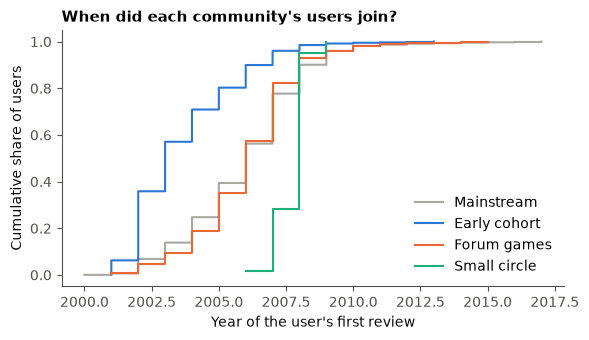

In [7]:
first_year = inter.groupby("user_id")["date"].min().dt.year
last_year = inter.groupby("user_id")["date"].max().dt.year
ucomm = cc.groupby("user_id")["comm"].first()
coh = pd.DataFrame(dict(comm=ucomm, first=first_year.reindex(ucomm.index), last=last_year.reindex(ucomm.index)))
cohort = coh.groupby("comm").agg(users=("first", "size"), median_first_year=("first", "median"),
                                 pct_joined_before_2006=("first", lambda x: round(100 * (x < 2006).mean(), 1)),
                                 median_last_year=("last", "median"))
cohort["KS_vs_rest"] = [round(float(ks_2samp(coh.loc[coh["comm"] == c, "first"], coh.loc[coh["comm"] != c, "first"])[0]), 3)
                        for c in cohort.index]
S["cohorts"] = cohort.to_dict("index")
print(cohort)

plt.figure(figsize=(6, 3.5))
for c in cohort.index:
    v = np.sort(coh.loc[coh["comm"] == c, "first"].values)
    plt.step(v, np.arange(1, len(v) + 1) / len(v), where="post", label=LABELS.get(c, c), color=COLORS.get(c))
plt.xlabel("Year of the user's first review"); plt.ylabel("Cumulative share of users")
plt.title("When did each community's users join?", loc="left"); plt.legend(frameon=False)
savefig("supp_cohorts")

**Result.** The game community joined at the same time as the mainstream (median first year 2006 in both; KS = 0.15, the smallest difference), so it is **not** a cohort; its users also stay active longer (median last year 2014 vs 2011–2012, correlational). Another community **is** an early cohort: 80 % joined before 2006 vs 35–39 % (KS = 0.48). The 64-user "small circle" all joined in 2007–2008 (KS = 0.61), suggesting a group that arrived together. Communities therefore form through **time** and **social play**, not only taste.

## 7. Forum-game activity and validity of the markers

In [8]:
gm = cc.groupby("comm").agg(users=("ui", "nunique"), reviews=("game", "size"), pct_game_reviews=("game", "mean"))
gm["pct_users_ever_played"] = cc.groupby(["comm", "user_id"])["game"].max().groupby("comm").mean()  # ≥ 1 game review
gm[["pct_game_reviews", "pct_users_ever_played"]] *= 100
S["game_by_comm"] = gm.round(1).to_dict("index")
S["game_comm_weight"] = dict(pct_users=round(100 * float(sizes[GAME_COMM] / sizes[BIG].sum()), 1),
                             pct_reviews=round(100 * float((cc["comm"] == GAME_COMM).mean()), 1))
print(gm.round(1)); print("Game community weight in the core:", S["game_comm_weight"])

# Which marker dominates in each community
mk = cc.loc[cc["game"], "review"].str.lower().str.extract("(" + "|".join(GAME_PATTERNS) + ")", flags=re.I)[0]
mk = mk.str.replace(r"\d+", "", regex=True).str.strip()
print(pd.DataFrame(dict(comm=cc.loc[cc["game"], "comm"], marker=mk)).groupby("comm")["marker"].value_counts().groupby(level=0).head(4))

      users  reviews  pct_game_reviews  pct_users_ever_played
comm                                                         
0      2360   116940               0.7                    7.5
1       608    53261               0.7                   14.0
2       445    64014              24.7                   77.8
3        64     3105               0.0                    0.0
Game community weight in the core: {'pct_users': 12.8, 'pct_reviews': 27.0}
comm  marker
0     zwt        405
      tag        234
      pac         86
      swap        76
1     zwt        138
      tag         65
      pac         44
      swap        38
2     zwt       6525
      tag       5716
      swap      1639
      pac        744
Name: count, dtype: int64


In [9]:
# Precision check of the most frequent marker ("tag"): read 20 random matches with their context
tag_re = re.compile(r"\btag(ged|ging)?\b", re.I)
tag_rev = cc[cc["review"].str.contains(tag_re)]
for _, r in tag_rev.sample(20, random_state=1).iterrows():
    m = tag_re.search(r["review"])
    print(f"[comm {r['comm']}] ...{r['review'][max(0, m.start()-100):m.end()+60]}...\n")

[comm 2] ...used a zesty Italian dressing which added a nice touch. Thanks Paula for sharing. Made for Cookbook Tag....

[comm 2] ...s on your preference.  Thanks for posting this recipe, ThatJodiGirl. Made for Top Favorites of 2008 Tag, as recommended by WiGal....

[comm 2] ...nto my keeper file.  Thanks for an absolutely delicious recipe, Sue Lau.  Made for Diabetic Cooking Tag Game....

[comm 2] ... and left the liquid in the other.  They turned out perfect.  Thanks for posting.  Made for Holiday tag....

[comm 2] ...me salt and pepper alone would have been very good for us. Made and reviewed for Kittencal's Recipe Tag Game....

[comm 2] ...nitely doesn't have a boxed cake mix taste! Made and reviewed for the Christmas 2011 Make My Recipe tag game....

[comm 2] ...ere still good in the oven. I used parsley and thyme instead of rosemary. Made for I Recommend Zaar Tag Game 2011....

[comm 2] ...rry bread which were very good too, but DH and I are fighting over this one!!  Made for I R

**Marker precision.** All 20 random matches of "tag" refer to forum games (e.g. *"Made for I Recommend Tag Game"*, *"Made for Zaar Cookbook Tag"*); with 20/20, precision is > 86 % at 95 % confidence. The reviews are genuine cooking reviews (they report changes to the recipe) and explicitly social (*"Thanks Paula"*, *"as recommended by WiGal"*).

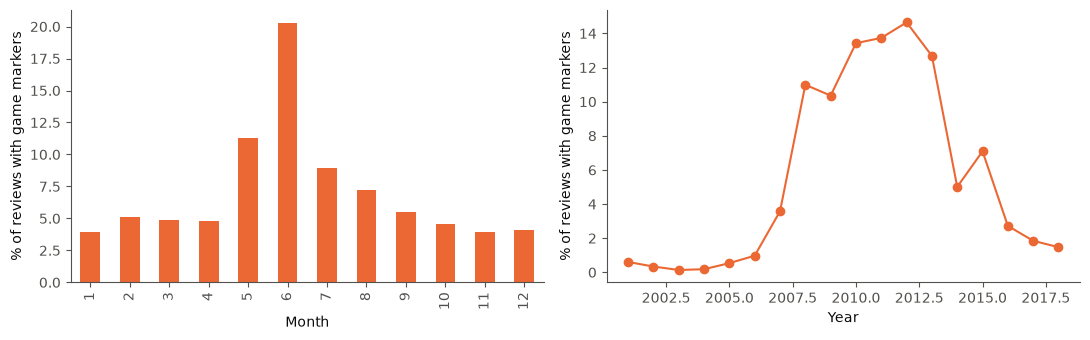

In [10]:
# When are game reviews written? Share of reviews with markers (normalised by total activity)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
cc.groupby(cc["date"].dt.month)["game"].mean().mul(100).plot.bar(ax=axes[0], color=COLORS[GAME_COMM])
axes[0].set_xlabel("Month"); axes[0].set_ylabel("% of reviews with game markers")
cc.groupby(cc["date"].dt.year)["game"].mean().mul(100).plot(ax=axes[1], marker="o", color=COLORS[GAME_COMM])
axes[1].set_xlabel("Year"); axes[1].set_ylabel("% of reviews with game markers")
savefig("supp_game_reviews_over_time")

**Result.** The game community (13 % of active users, 27 % of their reviews) has 25 % game reviews vs < 1 % elsewhere, and 78 % of its users played at least once vs 7–14 % elsewhere, so it is defined by games, not by a few hyperactive players. Game reviews peak in **May–July** (20 % of June reviews vs 4–5 % in other months), matching the Zaar World Tour calendar (late May–early July): an independent validation of the markers. In relative terms they peak in 2010–2012 (13–15 %) and fade after 2013, so the game community belongs to a specific period of the platform.

## 8. Does the review text reveal the community?

TF-IDF + logistic regression predicts the author's community from **one review**. To avoid inflated results: all reviews of a user are either in training or in test (StratifiedGroupKFold, 5 folds); at most 20 reviews per user and the same number of reviews per community; null model = community labels shuffled **across users**. Metric: balanced accuracy (chance = 0.25).

Versions: (1) all text; (2) no game markers, only words used by ≥ 50 users; (3) as 2, only recipes reviewed by ≥ 2 communities; (4) strict: also no forum jargon and no proper names; (5) as 4, shared recipes.

In [11]:
def sample_reviews(df, per_user=20, per_class=1500, seed=SEED):
    d = df[df["n_words"] >= 5].sample(frac=1, random_state=seed).groupby("user_id").head(per_user)
    return d.groupby("comm").head(min(per_class, d.groupby("comm").size().min()))

def classify(d, vocab=None, n_null=5, seed=SEED):
    vec = TfidfVectorizer(stop_words="english", min_df=3, max_features=20000, vocabulary=vocab)
    X = vec.fit_transform(d["review"]); y = d["comm"].values; groups = d["user_id"].values
    cv = StratifiedGroupKFold(5, shuffle=True, random_state=seed)
    clf = LogisticRegression(max_iter=3000, class_weight="balanced")
    acc = cross_val_score(clf, X, y, groups=groups, cv=cv, scoring="balanced_accuracy").mean()
    ucomm_ = d.groupby("user_id")["comm"].first(); nulls = []
    for i in range(n_null):
        perm = pd.Series(np.random.default_rng(seed + i).permutation(ucomm_.values), index=ucomm_.index)
        nulls.append(cross_val_score(clf, X, d["user_id"].map(perm).values, groups=groups, cv=cv,
                                     scoring="balanced_accuracy").mean())
    return dict(bal_acc=round(float(acc), 3), null_mean=round(float(np.mean(nulls)), 3),
                null_max=round(float(np.max(nulls)), 3), n=len(d)), clf.fit(X, y), vec, X

# Vocabularies: words used by ≥ 50 users, without markers ("clean"); also without jargon and proper names ("strict")
user_docs = cc.groupby("user_id")["review"].apply(lambda s: " ".join(s.tolist()[:50]))
vocab_users = CountVectorizer(stop_words="english", binary=True, min_df=50).fit(user_docs).vocabulary_
MARKER_TOKENS = re.compile(r"^(zwt\d*|zaar|pac|tag|tagged|tagging|swap|swapped|cookathon)$")
JARGON = {"game", "games", "tour", "cookbook", "prmr", "holiday", "challenge", "event", "team", "teams",
          "round", "menu", "region", "regions", "contest"}
caps, tot = Counter(), Counter()                     # proper names: capitalised mid-sentence > 80 % of the time
for txt in cc["review"].sample(min(100000, len(cc)), random_state=SEED):
    for t in re.findall(r"(?<=[a-z,] )([A-Za-z]+)", txt):
        tot[t.lower()] += 1; caps[t.lower()] += t[0].isupper()
PROPER = {x for x, n in tot.items() if n >= 20 and caps[x] / n > 0.8}
VOCAB_CLEAN = sorted(t for t in vocab_users if not MARKER_TOKENS.match(t) and not t.isdigit())
VOCAB_STRICT = [t for t in VOCAB_CLEAN if t not in JARGON and t not in PROPER]
print(f"{len(PROPER)} proper names removed; vocabulary clean = {len(VOCAB_CLEAN)}, strict = {len(VOCAB_STRICT)}")

d_all = sample_reviews(cc)
d_shared = sample_reviews(cc[cc.groupby("recipe_id")["comm"].transform("nunique") >= 2])
S["classifier"] = {}
for key, d, voc in [("1_all_text", d_all, None), ("2_no_markers", d_all, VOCAB_CLEAN),
                    ("3_no_markers_shared_recipes", d_shared, VOCAB_CLEAN),
                    ("4_strict", d_all, VOCAB_STRICT), ("5_strict_shared_recipes", d_shared, VOCAB_STRICT)]:
    res, clf, vec, X = classify(d, voc)
    S["classifier"][key] = res; print(key, res)
    if key == "4_strict":
        clf_s, vec_s, X_s = clf, vec, X

378 proper names removed; vocabulary clean = 3484, strict = 3346
1_all_text {'bal_acc': 0.512, 'null_mean': 0.251, 'null_max': 0.259, 'n': 5120}
2_no_markers {'bal_acc': 0.494, 'null_mean': 0.251, 'null_max': 0.259, 'n': 5120}
3_no_markers_shared_recipes {'bal_acc': 0.493, 'null_mean': 0.255, 'null_max': 0.264, 'n': 5120}
4_strict {'bal_acc': 0.483, 'null_mean': 0.248, 'null_max': 0.256, 'n': 5120}
5_strict_shared_recipes {'bal_acc': 0.482, 'null_mean': 0.256, 'null_max': 0.265, 'n': 5120}


In [12]:
# Confusion matrix and most characteristic words of the strict model
pred = cross_val_predict(LogisticRegression(max_iter=3000, class_weight="balanced"), X_s, d_all["comm"].values,
                         groups=d_all["user_id"].values, cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED))
cm = pd.crosstab(d_all["comm"].values, pred, normalize="index").reindex(index=BIG, columns=BIG).fillna(0).round(2)
S["confusion_strict"] = cm.to_dict("index"); print(cm)
voc = np.array(vec_s.get_feature_names_out())
for c, r_ in zip(clf_s.classes_, clf_s.coef_):
    print(f"{LABELS.get(c, c)}: {', '.join(voc[np.argsort(-r_)[:15]])}")

col_0     0     1     2     3
row_0                        
0      0.40  0.27  0.22  0.10
1      0.29  0.32  0.27  0.12
2      0.21  0.27  0.41  0.11
3      0.08  0.06  0.08  0.79
Mainstream: husband, thank, turned, cups, definitely, tasted, vinegar, min, bananas, yum, ll, need, sorry, substituted, pesto
Early cohort: thanks, easy, ve, keeper, mixture, incredible, exactly, needed, grown, freezer, hubby, today, actually, lime, crockpot
Forum games: reviewed, written, drink, spring, sharing, posting, lovely, wonderful, nice, lol, everyday, cooked, milk, worcestershire, quick
Small circle: loved, delicious, awesome, excellent, sushi, ribs, nuts, great, soon, gone, anytime, company, table, couldn, went


**Result.** Balanced accuracy 0.51 vs ≤ 0.27 for the null. It barely changes after removing markers, jargon and 378 proper names (0.48) or when using only recipes reviewed by several communities (0.48): communities differ in **how** they write, not only in game jargon or in which recipes they review. Per community: 0.79 (small circle, only 64 users), 0.41 (games), 0.40 (mainstream), 0.32 (early cohort); the three large communities are often confused. Without explicit jargon, the game community's characteristic words (*reviewed, written, posting, sharing, lovely, lol*) reflect a polite forum register rather than a culinary vocabulary. The signal is moderate; the characteristic words are descriptive, not evidence.

## 9. Do game reviews give higher ratings?

If reviews written inside a social game gave higher ratings, ratings would be a less reliable signal of recipe quality. Each rating is compared with the mean rating of the **same recipe** (rating 0 = "no stars" excluded); null = labels shuffled within each recipe. Stricter control: each user's game reviews vs their own non-game reviews.

In [13]:
rr = cc[cc["rating"] > 0].copy()
rr["dev"] = rr["rating"] - rr.groupby("recipe_id")["rating"].transform("mean")

def perm_within(groups, labels, rng):
    # Shuffle labels within each group
    order0 = np.argsort(groups, kind="stable"); order1 = np.lexsort((rng.random(len(groups)), groups))
    out = np.empty_like(labels); out[order0] = labels[order1]; return out

def perm_test(obs, null):
    return round(float(obs), 4), [round(float(np.percentile(null, 2.5)), 4), round(float(np.percentile(null, 97.5)), 4)], \
           round(float(((np.abs(null) >= abs(obs)).sum() + 1) / (len(null) + 1)), 4)

# (a) By community, within recipes reviewed by ≥ 2 communities
r1 = rr[rr.groupby("recipe_id")["comm"].transform("nunique") >= 2].reset_index(drop=True)
obs1 = r1.groupby("comm")["dev"].mean()
null1 = np.array([pd.Series(r1["dev"].values).groupby(perm_within(r1["recipe_id"].values, r1["comm"].values, rng)).mean()
                  .reindex(obs1.index).values for _ in range(500)])
S["rating_dev_by_comm"] = {int(c): dict(zip(["dev_stars", "null_95", "p"], perm_test(obs1[c], null1[:, i])))
                           for i, c in enumerate(obs1.index)}

# (b) Game vs non-game reviews of the same recipe
r2 = rr[rr.groupby("recipe_id")["game"].transform("nunique") == 2].reset_index(drop=True)
diff = lambda g: r2["dev"].values[g].mean() - r2["dev"].values[~g].mean()
null2 = np.array([diff(perm_within(r2["recipe_id"].values, r2["game"].values, rng)) for _ in range(500)])
S["game_vs_nongame_same_recipe"] = dict(zip(["diff_stars", "null_95", "p"], perm_test(diff(r2["game"].values), null2)))

# (c) Same user: their game reviews vs their other reviews
r3 = rr[rr.groupby("user_id")["game"].transform("nunique") == 2].reset_index(drop=True)
def user_diff(game):
    m = pd.DataFrame(dict(dev=r3["dev"].values, g=game, u=r3["user_id"].values)).groupby(["u", "g"])["dev"].mean().unstack()
    return float((m[True] - m[False]).mean())
null3 = np.array([user_diff(perm_within(r3["user_id"].values, r3["game"].values, rng)) for _ in range(300)])
S["game_vs_nongame_same_user"] = dict(zip(["diff_stars", "null_95", "p"], perm_test(user_diff(r3["game"].values), null3)),
                                      n_users=int(r3["user_id"].nunique()))
S["pct_five_stars"] = dict(game=round(100 * float((rr.loc[rr["game"], "rating"] == 5).mean()), 1),
                           non_game=round(100 * float((rr.loc[~rr["game"], "rating"] == 5).mean()), 1))
for k in ["rating_dev_by_comm", "game_vs_nongame_same_recipe", "game_vs_nongame_same_user", "pct_five_stars"]:
    print(k, S[k])

rating_dev_by_comm {0: {'dev_stars': -0.0418, 'null_95': [-0.0023, 0.002], 'p': 0.002}, 1: {'dev_stars': 0.0337, 'null_95': [-0.0037, 0.0044], 'p': 0.002}, 2: {'dev_stars': 0.0458, 'null_95': [-0.0029, 0.0029], 'p': 0.002}, 3: {'dev_stars': 0.0947, 'null_95': [-0.0164, 0.0172], 'p': 0.002}}
game_vs_nongame_same_recipe {'diff_stars': 0.0539, 'null_95': [-0.0067, 0.0064], 'p': 0.002}
game_vs_nongame_same_user {'diff_stars': 0.0013, 'null_95': [-0.0237, 0.0248], 'p': 0.897, 'n_users': 605}
pct_five_stars {'game': 86.5, 'non_game': 79.6}


**Result (negative).** For the same recipe, game reviews give +0.05 stars (86.5 % vs 79.6 % five-star; p < 0.01), but comparing each user with themselves the difference disappears (+0.001 stars, p = 0.92, 606 users). Game players are more generous raters in general; the game context does not inflate ratings, and the effect is tiny anyway. *Limitation:* reciprocity between specific users is not tested.

## 10. Hand-labelled validation of the markers

1. The next cell creates `hand_labels.csv` with 52 reviews (13 per community), **without** the community (blind labelling); the key is in `hand_labels_key.csv`.
2. Fill `social_game` with 1/0 (mentions a forum game or event, e.g. "Made for X"). Optional: `mentions_person` (another user by name).
3. Save as CSV with the same name (separator `;`). For inter-annotator agreement, a second person labels a copy saved as `hand_labels_B.csv`.
4. Run the evaluation cell: precision and recall of the regex, and Cohen's kappa if there are two labellers.

In [14]:
LAB_FILE, KEY_FILE, LAB_FILE_B = "hand_labels.csv", "hand_labels_key.csv", "hand_labels_B.csv"
if not os.path.exists(LAB_FILE):
    smp = cc[cc["n_words"] >= 5].sample(frac=1, random_state=SEED).groupby("comm").head(13).sample(frac=1, random_state=1)
    smp = smp.reset_index(drop=True); smp["item"] = np.arange(len(smp))
    smp[["item", "review"]].assign(social_game="", mentions_person="").to_csv(LAB_FILE, sep=";", index=False, encoding="utf-8-sig")
    smp[["item", "comm", "user_id", "recipe_id", "rating", "game"]].to_csv(KEY_FILE, sep=";", index=False)
    print(f"Created {LAB_FILE} ({len(smp)} reviews). Label it and run the next cell.")
else:
    print(f"{LAB_FILE} already exists (not overwritten).")

Created hand_labels.csv (52 reviews). Label it and run the next cell.


In [15]:
lab = pd.read_csv(LAB_FILE, sep=";", encoding="utf-8-sig")
if lab["social_game"].isna().all():
    print("Not labelled yet.")
else:
    lab = lab.merge(pd.read_csv(KEY_FILE, sep=";"), on="item").dropna(subset=["social_game"])
    truth, regex = lab["social_game"].astype(int) == 1, lab["game"].astype(bool)
    S["hand_labels"] = dict(n=len(lab), n_game_by_hand=int(truth.sum()),
                            precision=round(float((truth & regex).sum() / max(1, regex.sum())), 2),
                            recall=round(float((truth & regex).sum() / max(1, truth.sum())), 2),
                            pct_social_by_comm=(lab.groupby("comm")["social_game"].mean() * 100).round(0).to_dict())
    if os.path.exists(LAB_FILE_B):
        lb = pd.read_csv(LAB_FILE_B, sep=";", encoding="utf-8-sig")[["item", "social_game"]].rename(columns={"social_game": "b"})
        both = lab.merge(lb, on="item").dropna(subset=["b"])
        S["hand_labels"]["cohen_kappa"] = round(float(cohen_kappa_score(both["social_game"].astype(int), both["b"].astype(int))), 2)
    print(S["hand_labels"])

Not labelled yet.


## 11. Paper figures

In [ ]:
# Figure style for the paper: drawn at PNAS full-page width (7 in = 17.8 cm), so 7 pt here is 7 pt in print
PNAS_W = 7.0
plt.rcParams.update({"font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7, "xtick.labelsize": 6.5,
                     "ytick.labelsize": 6.5, "legend.fontsize": 6.5, "axes.linewidth": 0.6,
                     "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5,
                     "ytick.major.size": 2.5, "pdf.fonttype": 42,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
NEUTRAL = "#3d3d3a"            # bars that are not about one community (avoids reusing a community colour)

def savefig(name):
    """Save PNG (preview) and PDF (for Overleaf); bbox 'tight' so no title is ever cut off."""
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
    plt.savefig(f"{FIG_DIR}/{name}.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()

In [ ]:
# Figure 1: the network separates forum-game players without using any text
# A: co-review backbone, coloured by Louvain community; dark ring = user with > 10 % game reviews (text).
# B: share of each community's reviews with game markers, against a null that shuffles community labels between users.
TOP_N, RING = 1000, 0.10
comms = BIG; names = [LABELS.get(c, str(c)) for c in comms]
user_game = cc.groupby("ui")["game"].mean()
top = [n for n, _ in sorted(Gu.degree(weight="weight"), key=lambda x: -x[1])[:TOP_N] if n in comm_of]
Hn = Gu.subgraph(top).copy()
pos = nx.spring_layout(Hn, weight="weight", seed=SEED, iterations=100)
nodes_f = list(Hn.nodes()); xy = np.array([pos[n] for n in nodes_f])
lo, hi = np.percentile(xy, 1, axis=0), np.percentile(xy, 99, axis=0); pad = 0.04 * (hi - lo)
deg = np.array([Hn.degree(n) for n in nodes_f]); size = 1.5 + 10 * deg / deg.max()
e_all = list(Hn.edges())
e_idx = np.random.default_rng(SEED).choice(len(e_all), size=min(15000, len(e_all)), replace=False)
segs = [(pos[e_all[i][0]], pos[e_all[i][1]]) for i in e_idx]
cvec = np.array([comm_of[n] for n in nodes_f]); gvec = np.array([user_game.get(n, 0) for n in nodes_f])

# Null for B: shuffle community labels between users (sizes kept), recompute each community's game share
ucomm = cc.groupby("ui")["comm"].first(); ugame = cc.groupby("ui")["game"].agg(["sum", "size"])
null_share = []
for i in range(1000):
    lab = pd.Series(np.random.default_rng(SEED + i).permutation(ucomm.values), index=ucomm.index)
    g = ugame.groupby(lab.reindex(ugame.index)).sum()
    null_share.append(100 * g["sum"] / g["size"])
null_share = pd.DataFrame(null_share)
S["fig1_null_pct_game"] = dict(lo=round(float(null_share.quantile(0.025).min()), 1), hi=round(float(null_share.quantile(0.975).max()), 1))

fig, (a, b) = plt.subplots(1, 2, figsize=(PNAS_W, 3.3), gridspec_kw=dict(width_ratios=[1.75, 1]))
a.add_collection(LineCollection(segs, colors="#c3c2b7", linewidths=0.15, alpha=0.10, zorder=0))
a.set_xlim(lo[0] - pad[0], hi[0] + pad[0]); a.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
a.set_axis_off(); a.set_aspect("equal")
for c in sorted(comms, key=lambda c: c != 0):            # mainstream drawn first (underneath)
    m = cvec == c
    a.scatter(xy[m, 0], xy[m, 1], s=size[m], c=COLORS.get(c), linewidths=0, zorder=1 + (c != 0))
m = gvec > RING
a.scatter(xy[m, 0], xy[m, 1], s=size[m] + 6, facecolors="none", edgecolors=INK, linewidths=0.45, zorder=5)
hand = [Patch(color=COLORS.get(c), label=LABELS.get(c, c)) for c in comms]
hand.append(plt.Line2D([], [], marker="o", ls="", mfc="none", mec=INK, mew=0.6, ms=4, label=f"> {RING:.0%} game reviews (text)"))
a.legend(handles=hand, loc="upper left", bbox_to_anchor=(0, 0.04), ncol=3, frameon=False, handlelength=1, columnspacing=1)
a.set_title(f"A. Co-review network, {TOP_N} most active users", loc="left")

y = gm.loc[comms, "pct_game_reviews"].values; xb = np.arange(len(comms))
qlo, qhi = null_share[comms].quantile(0.025).values, null_share[comms].quantile(0.975).values
b.axhline(100 * cc["game"].mean(), color=MUTED, lw=0.6, ls=":", zorder=0)
b.text(0.5, 100 * cc["game"].mean() + 0.4, f"all {100 * cc['game'].mean():.0f}%",
       ha="left", va="bottom", color=MUTED, fontsize=6)
b.bar(xb, y, 0.6, color=[COLORS.get(c) for c in comms], zorder=2)
b.errorbar(xb + 0.38, (qlo + qhi) / 2, yerr=(qhi - qlo) / 2, fmt="none", ecolor="#7a7974", elinewidth=0.9,
           capsize=1.8, capthick=0.9, zorder=3)
for xi, v in zip(xb, y):
    b.text(xi, v + 0.5, f"{v:.0f}%" if v >= 1 else f"{v:.1f}%", ha="center", va="bottom", color=INK)
b.set_xticks(xb); b.set_xticklabels([n.replace(" ", "\n") for n in names]); b.tick_params(axis="x", length=0)
b.set_ylabel("% of the community's reviews\nwith forum-game markers"); b.set_ylim(0, max(y) * 1.22)
b.legend(handles=[plt.Line2D([], [], color="#7a7974", marker="|", ms=6, mew=0.9, lw=0.9,
                             label="Null: community labels shuffled\nbetween users (95% range)")],
         frameon=False, loc="upper left", bbox_to_anchor=(-0.02, 1.02))
b.set_title("B. Only one community plays", loc="left")
plt.tight_layout(w_pad=1.0)
savefig("fig1_network_vs_game_reviews")

In [ ]:
# Figure 2: the game community is robust to the analysis choices, and game reviews follow the event calendar
# A: for every re-run, % game reviews inside the community that best matches the reference game community (orange)
#    vs the rest of the network (grey); J = Jaccard overlap of its users with the reference community.
fig, (a, b) = plt.subplots(1, 2, figsize=(PNAS_W, 2.9), gridspec_kw=dict(width_ratios=[1.35, 1]))
ref = (rob.KU == KU) & (rob.KR == KR) & (rob.alpha == ALPHA)
blocks = [("Louvain seed", rob[ref], lambda r: f"seed {r.seed}"),
          ("Backbone α", rob[(rob.KU == KU) & (rob.KR == KR) & (rob.alpha != ALPHA)], lambda r: f"α = {r.alpha:g}"),
          ("Core thresholds", rob[(rob.KU != KU) | (rob.KR != KR)], lambda r: f"≥{r.KU} recipes, ≥{r.KR} reviewers")]
yv, ylab, ytxt, yy = [], [], [], 0
for bi, (bname, dfb, fmt) in enumerate(blocks):
    if bi % 2 == 1:
        a.axhspan(-(yy + len(dfb)) + 0.45, -yy + 1.35, color="#f1f0ea", lw=0, zorder=0)
    a.text(-1.0, -yy + 0.85, bname, ha="left", va="bottom", fontweight="bold", color=MUTED, fontsize=6.5)
    for r in dfb.itertuples():
        y_ = -yy
        a.plot([100 * r.game_share_rest, 100 * r.game_share], [y_, y_], color="#c3c2b7", lw=1, zorder=1)
        a.scatter(100 * r.game_share_rest, y_, s=14, color="#9b9a94", zorder=2, lw=0)
        a.scatter(100 * r.game_share, y_, s=14, color=COLORS[GAME_COMM], zorder=2, lw=0)
        a.text(31.5, y_, f"J = {r.jaccard_vs_ref:.2f}", va="center", ha="left", color=MUTED, fontsize=6)
        yv.append(y_); ylab.append(fmt(r)); yy += 1
    yy += 1.6
a.set_yticks(yv); a.set_yticklabels(ylab, fontsize=6); a.tick_params(axis="y", length=0)
a.set_xlim(-1, 36); a.set_ylim(min(yv) - 0.7, 1.5); a.spines["left"].set_visible(False)
a.set_xlabel("% of reviews with forum-game markers")
a.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=COLORS[GAME_COMM], ms=4, label="Game community"),
                  plt.Line2D([], [], marker="o", ls="", color="#9b9a94", ms=4, label="Rest of network")],
         frameon=False, loc="lower center", bbox_to_anchor=(0.45, 0.99), ncol=2, borderaxespad=0)
a.set_title("A. The game community reappears in every re-run", loc="left", pad=17)

mshare = cc.groupby(cc["date"].dt.month)["game"].mean() * 100
b.axvspan(4.5, 7.5, color=COLORS[GAME_COMM], alpha=0.12, lw=0)
b.text(6, mshare.max() * 1.04, "Zaar World Tour\n(late May–early July)", ha="center", va="bottom", color=MUTED, fontsize=6)
b.bar(mshare.index, mshare.values, 0.7, color=COLORS[GAME_COMM])
b.set_xticks(range(1, 13)); b.set_xticklabels(list("JFMAMJJASOND")); b.set_ylim(0, mshare.max() * 1.3)
b.set_xlabel("Month (all years pooled)"); b.set_ylabel("% of core reviews with game markers")
b.set_title("B. Game reviews peak with the World Tour", loc="left", pad=17)
plt.tight_layout(w_pad=1.5)
savefig("fig2_game_activity_robustness_calendar")

In [ ]:
# Figure 3: the review text alone reveals the reviewer's community
# Extra check: the same strict model on the three large communities only (small circle removed), chance = 1/3
d3 = d_all[d_all["comm"] != 3]
X3 = TfidfVectorizer(stop_words="english", vocabulary=VOCAB_STRICT).fit_transform(d3["review"])
cv3 = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
lr3 = LogisticRegression(max_iter=3000, class_weight="balanced")
acc3 = cross_val_score(lr3, X3, d3["comm"].values, groups=d3["user_id"].values, cv=cv3, scoring="balanced_accuracy").mean()
u3 = d3.groupby("user_id")["comm"].first(); null3 = []
for i in range(5):
    perm = pd.Series(np.random.default_rng(SEED + i).permutation(u3.values), index=u3.index)
    null3.append(cross_val_score(lr3, X3, d3["user_id"].map(perm).values, groups=d3["user_id"].values, cv=cv3,
                                 scoring="balanced_accuracy").mean())
S["classifier"]["6_strict_three_large"] = dict(bal_acc=round(float(acc3), 3), null_max=round(float(max(null3)), 3),
                                               chance=round(1 / 3, 3), n=len(d3))
print("Strict model, three large communities:", S["classifier"]["6_strict_three_large"])

fig, (a, b) = plt.subplots(1, 2, figsize=(PNAS_W, 2.75), gridspec_kw=dict(width_ratios=[1.25, 1]))
vers = [("1_all_text", "All words"), ("2_no_markers", "– game markers"), ("3_no_markers_shared_recipes", "– markers, shared recipes only"),
        ("4_strict", "– jargon and names"), ("5_strict_shared_recipes", "– jargon/names, shared recipes only")]
acc = [S["classifier"][k]["bal_acc"] for k, _ in vers]; nmax = max(S["classifier"][k]["null_max"] for k, _ in vers)
yb = np.arange(len(vers))[::-1]
a.axvspan(0, nmax, color="#e1e0d9", lw=0, zorder=0)
a.axvline(0.25, color=MUTED, lw=0.7, ls="--", zorder=1)
a.hlines(yb, 0, acc, color="#c3c2b7", lw=0.8, zorder=1)
a.scatter(acc, yb, s=22, color=NEUTRAL, zorder=2, lw=0)
for yi, v in zip(yb, acc):
    a.text(v + 0.015, yi, f"{v:.2f}", va="center", color=INK)
a.set_yticks(yb); a.set_yticklabels([l for _, l in vers]); a.tick_params(axis="y", length=0); a.spines["left"].set_visible(False)
a.set_xlim(0, 0.7); a.set_xlabel("Balanced accuracy, one review → community")
a.text(0.258, -0.85, "chance", ha="left", va="center", color=MUTED, fontsize=6)
a.text(0.115, -0.85, "shuffled null", ha="center", va="center", color=MUTED, fontsize=6)
a.set_ylim(-1.2, len(vers) - 0.4)
a.set_title("A. Removing the game words barely matters", loc="left")

cmv = cm.loc[comms, comms].values
b.imshow(cmv, cmap="Greys", vmin=0, vmax=1.15)
for i in range(len(comms)):
    for j in range(len(comms)):
        b.text(j, i, f"{cmv[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
               color="white" if cmv[i, j] > 0.55 else INK, fontweight="bold" if i == j else "normal")
b.set_xticks(range(len(comms))); b.set_xticklabels([n.replace(" ", "\n") for n in names])
b.set_yticks(range(len(comms))); b.set_yticklabels(names)
for t, c in zip(b.get_yticklabels(), comms): t.set_color(COLORS.get(c) if c != 0 else INK)
b.tick_params(length=0)
b.set_xlabel("Predicted community"); b.set_ylabel("True community")
for sp in b.spines.values(): sp.set_visible(False)
b.set_title("B. Where the model is right (rows sum to 1)", loc="left")
plt.tight_layout(w_pad=1.2)
savefig("fig3_text_reveals_community")

**Draft captions** (figures are drawn at PNAS full width, 7 in; use the PDFs in `figures/` in Overleaf)

**Fig. 1. The co-review network separates forum-game players without using any text.** (A) Backbone of the user–user co-review network (the 1,000 users with the highest strength), coloured by Louvain community; Louvain uses only who reviewed which recipe. Black rings mark users with more than 10% of their reviews containing forum-game markers (e.g. "Made for ZWT8"), detected afterwards from the text: 148 of the 170 ringed users fall in one community. (B) Share of each community's reviews with game markers. Whiskers: 95% range when community labels are shuffled between users (1,000 shuffles); dotted line: all active users (7%). The forum-game community (25%) lies far above its null range (4.5–10.6%); the other three lie below theirs.

**Fig. 2. The game community is robust and its activity follows the game calendar.** (A) Each row re-runs the pipeline with a different Louvain seed, disparity-filter α or core threshold (minimum recipes per user, minimum reviewers per recipe). Orange: share of game reviews in the community that best matches the reference game community; grey: rest of the network. J: Jaccard overlap of its users with the reference community. (B) Share of core reviews with game markers by calendar month, all years pooled; shaded: Zaar World Tour period.

**Fig. 3. The review text alone reveals the reviewer's community.** (A) Balanced accuracy of a TF-IDF + logistic-regression classifier that predicts the reviewer's community from a single review, with users held out across folds. Rows remove information step by step: game markers, then game jargon and proper names, and restrict to recipes reviewed by several communities. Grey band: shuffled-label null (maximum of 5 shuffles); dashed line: chance (0.25). (B) Confusion matrix of the strictest model; each row gives how the reviews of one true community are classified (rows sum to 1). The small circle (64 users) is the easiest to recognise; on the three large communities alone the strict model reaches 0.42 (null ≤ 0.34, chance 0.33).

## 12. Summary of key numbers

In [19]:
print(json.dumps(S, indent=1, default=str, ensure_ascii=False))

{
 "data": {
  "users": 226570,
  "recipes": 231637,
  "reviews": 1132367,
  "pct_users_one_review": 73.4,
  "pct_five_stars": 72.1,
  "pct_reviews_with_game_marker": 7.87
 },
 "core": {
  "users": 3477,
  "recipes": 10636,
  "edges": 237320
 },
 "projection": {
  "edges": 2799026,
  "density": 0.463
 },
 "alpha_choice": [
  {
   "alpha": 0.01,
   "edges": 35503,
   "pct_users_in_giant": 98.4
  },
  {
   "alpha": 0.05,
   "edges": 130905,
   "pct_users_in_giant": 100.0
  },
  {
   "alpha": 0.1,
   "edges": 258455,
   "pct_users_in_giant": 100.0
  }
 ],
 "backbone": {
  "edges": 130905,
  "density": 0.0217
 },
 "louvain": {
  "best_seed": 8,
  "Q": 0.203,
  "sizes": {
   "0": 2360,
   "1": 608,
   "2": 445,
   "3": 64
  }
 },
 "null_model": {
  "Q_real": 0.203,
  "Q_null_mean": 0.06,
  "Q_null_sd": 0.003,
  "z": 50.9
 },
 "stability": {
  "NMI_mean": 0.517,
  "NMI_min": 0.395,
  "n_communities": [
   4,
   4,
   3,
   4,
   4,
   5,
   4,
   4,
   4,
   4
  ]
 },
 "robustness": [
  {
  